# 3장 1강: 편향-분산 트레이드오프와 과적합/과소적합 진단

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 모델 복잡도와 과적합/과소적합의 관계를 확인합니다.

- 모델이 너무 단순할 때 나타나는 **고편향(과소적합)** 상태를 확인합니다.
- 모델이 너무 복잡할 때 나타나는 **고분산(과적합)** 상태를 확인합니다.
- `learning_curve()`를 이용하여 학습곡선을 확인합니다.
- `validation_curve()`를 이용하여 모델 복잡도에 따른 Train / Validation 성능 변화를 확인합니다.
- `train-valid gap`을 이용하여 모델 상태를 진단합니다.
- 진단 결과에 맞는 대응 전략을 선택합니다.

> 이 실습에서는 3장 1강 교안에서 다룬 편향-분산, 학습곡선, 검증곡선, train-valid gap, 과적합/과소적합 대응 전략만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- numpy
- matplotlib
- scikit-learn
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택의 여러 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

이번 강의의 목적은 예측 성능 자체를 최대화하는 것이 아니라 **모델 복잡도에 따라 Train / Validation 성능이 어떻게 달라지는지 진단하는 것**입니다.

### 사용할 특성

결측치 처리 자체가 이번 강의의 학습 목표가 아니므로, 결측치가 없는 숫자형 특성 중 일부만 사용합니다.

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `TotalBsmtSF`
- `1stFlrSF`
- `YearBuilt`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 특성과 예측 대상을 선택합니다.
3. 결측치가 없는지 확인합니다.
4. 데이터 크기와 기초 통계량을 확인합니다.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import learning_curve, validation_curve

house = pd.read_csv("ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "1stFlrSF",
    "YearBuilt"
]

X = house[features]
Y = house["SalePrice"]

print("X 크기:", X.shape)
print("Y 크기:", Y.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

print("\n[기초 통계량]")
display(X.describe())

X 크기: (1460, 6)
Y 크기: (1460,)

[결측치]


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
TotalBsmtSF,0
1stFlrSF,0
YearBuilt,0



[기초 통계량]


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,1stFlrSF,YearBuilt
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,6.099315,1515.463699,1.767123,1057.429452,1162.626712,1971.267808
std,1.382997,525.480383,0.747315,438.705324,386.587738,30.202904
min,1.000000,334.000000,0.000000,0.000000,334.000000,1872.000000
25%,5.000000,1129.500000,1.000000,795.750000,882.000000,1954.000000
50%,6.000000,1464.000000,2.000000,991.500000,1087.000000,1973.000000
75%,7.000000,1776.750000,2.000000,1298.250000,1391.250000,2000.000000
max,10.000000,5642.000000,4.000000,6110.000000,4692.000000,2010.000000


In [3]:
house.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

---

# 필수 1. 학습곡선으로 과소적합과 과적합 진단

## 배경

학습곡선은 **학습 데이터의 양을 늘려가며 Train score와 Validation score가 어떻게 변하는지 확인하는 그래프**입니다.

이번 문제에서는 같은 Ames Housing 데이터에 대해 두 개의 결정트리를 비교합니다.

- `max_depth=2` → 복잡도가 낮은 모델
- `max_depth=None` → 깊이를 제한하지 않은 복잡한 모델

## 문제 1. `max_depth=2` 모델의 학습곡선을 그리세요.

### 요구사항

1. `DecisionTreeRegressor(max_depth=2, random_state=42)`를 만듭니다.
2. `learning_curve()`를 사용합니다.
3. `cv=5`를 사용합니다.
4. 학습 데이터 비율은 `np.linspace(0.1, 1.0, 6)`을 사용합니다.
5. 각 구간의 Train score와 Validation score 평균을 계산합니다.
6. 두 점수를 하나의 그래프에 표시합니다.
7. 두 곡선이 어디에서 수렴하는지 확인합니다.

### 확인 포인트

- 두 점수가 모두 낮은 수준에서 가까워지는가?
- 모델이 너무 단순한 상태인지 판단할 수 있는가?

,train_size,train_score,validation_score
0,116,0.701773,0.577790
1,327,0.669689,0.600452
2,537,0.664581,0.594019
3,747,0.653289,0.600512
4,957,0.645513,0.574357
5,1168,0.634121,0.602378


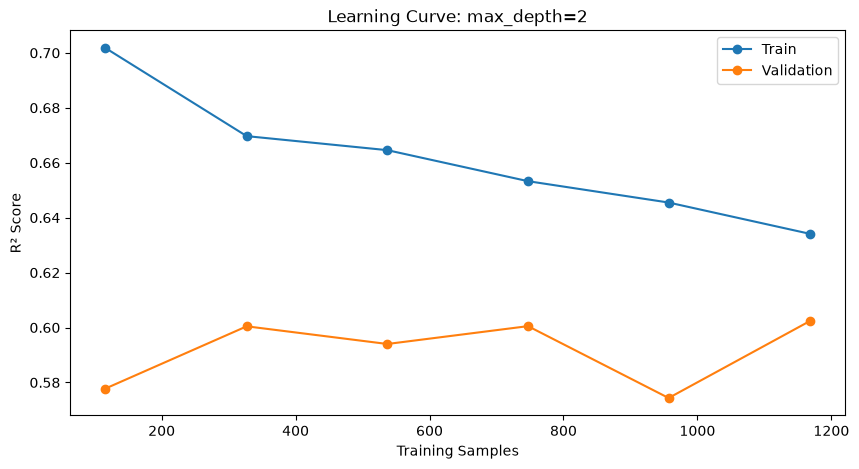

In [4]:
# TODO
# max_depth=2 결정트리의 학습곡선을 그려보세요.
shallow_tree = DecisionTreeRegressor(max_depth=2, random_state=42)

train_sizes, train_scores, valid_scores = learning_curve(
    shallow_tree, X, Y, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 6),
    n_jobs=-1
)

train_mean_shallow = train_scores.mean(axis=1)
valid_mean_shallow = valid_scores.mean(axis=1)

plt.figure(figsize=(10, 5))

plt.plot(train_sizes, train_mean_shallow, marker="o", label="Train")
plt.plot(train_sizes, valid_mean_shallow, marker="o", label="Validation")

# 학습 점수와 검증 점수의 평균 계산
train_mean_shallow = train_scores.mean(axis=1)
valid_mean_shallow = valid_scores.mean(axis=1)

# 결과표 생성
result_shallow = pd.DataFrame({
    "train_size": train_sizes,
    "train_score": train_mean_shallow,
    "validation_score": valid_mean_shallow
})

display(result_shallow)

plt.xlabel("Training Samples")
plt.ylabel("R² Score")
plt.title("Learning Curve: max_depth=2")
plt.legend()
plt.show()

In [5]:
# 그래프 설명(학습곡선)
# 학습곡선(Learning Curve)에서는 Train Score(학습 점수)와 Validation Score(검증 점수)의 높이와 차이를 보고 과적합과 과소적합을 판단
# DecisionTreeRegressor는 R²(결정계수)를 사용하므로, R²가 높을수록 예측 성능이 좋다는 기준으로
# -(1). 과적합(Overfitting) --> Train 높음 / Validation 낮음 : 학습 데이터에는 잘 맞지만 새로운 데이터에는 잘 맞지 않는 상태.
#                                                           두 점수의 차이가 크게 유지되면 과적합 가능성이 높다. 
# -(2). 과소적합(Underfitting) --> Train 낮음 / Validation 낮음 : 학습 데이터에서도 충분한 패턴을 찾지 못한 상태, 
#                                                              두 점수가 낮은 수준에서 비슷하게 나타나면 과소적합 가능성이 높다.
# -(3). 적절한 학습(Good Fit) --> Train 높음 / Validation 높음 : 학습 데이터와 검증 데이터에서 모두 좋은 성능을 보임. 
#                                                             두 점수가 높은 수준에서 가까워지면 일반화 성능이 양호하다고 판단할 수 있다.

# max_depth=2인 결정트리의 학습곡선에서 학습 데이터가 증가할수록 Train R²는 약 0.70에서 0.63으로 감소하였으며, 
# Validation R²는 약 0.60 수준에서 정체되는 경향을 보였다. 
# 두 점수의 차이는 점차 감소하였으나, 모두 상대적으로 낮은 수준에서 수렴하고 있어 모델의 복잡도가 부족한 과소적합 가능성이 있다. 
# 따라서 max_depth를 증가시켜 모델의 성능 변화를 비교할 필요가 있다.
# 학습곡선에서 점수가 불규칙하게 변동하거나 감소하는 경우 데이터 전처리 문제, 데이터 분포 차이, 모델의 복잡도 등을 점검할 필요가 있다.
# 성능이 떨어질 때는 하이퍼 파라미터 튜닝, 데이터 전처리 다시 하기, 외부데이터 연계 등의 방법 중 그래프가 일정하지 않고 변동하면 데이터 전처리를
# 다시해야 한다고 판단할 수 있어야 한다. 
# max_depth를 증가시켜 모델 복잡도에 따른 성능 변화를 비교하는 것도 필요하다.
# 과적합을 증명하는 것은 어려움, 학습곡선(학습 성능과 검증 성능의 변화를 그래프로 보는 것)과 로스를 보고 판단할 수 있다. 

R² : 결정계수
R²= 1 : 실제값과 예측값이 일치
R² = 0 : 실제 평균만 예측, 충분히 설명하지 못함. 
R² 이 1에 가까울수록 모델이 그만큼 데이터에 대한 설명력을 가지고 있다. 

학습샘플 수 116: Train R²의 평균 0.70 / Validation R²의 평균 0.57
-> 판단: 적은 학습데이터에서 비교적 차이가 큼(0.13)

학습샘플 수 327: Train R²의 평균 0.66 / Validation R²의 평균 0.60
-> 판단: Train데이터의 R²은 0.04감소 Validation의 R²은 0.03상승 -> 격차가 줄어들었다.
               
학습샘플 수 537: Train R²의 평균0.66 / Validation의 R²의 평균 0.59
-> 판단: Train R²은 유지 Valdation R²은 0.01감소 

학습샘플 수 1,168 : Train R²의 평균 0.63 / Validation R²의 평균 0.60
-> 판단: 평균점수 차이가 가장 낮다. 

Train R²의 평균 0.66 / Validation R²의 평균 0.59

Q. 이 표와 그래프를 보고 과소적합 또는 편향의 신호를 알 수 있는가?
->R² 값  Train과 Validation에서 약 0.60정도, 즉 데이터에 대한 파악이 약60점 정도라고 보인다.

Q. R² 값이 비교적 0.60으로 낮기 때문에 모델이 해당 데이터에 대한 충분한 파악을 하지 못한 과소적합을 의심해 볼 수 있다. 
단 R²가 0.60 이면 무조건 낮다. <-기준이 없기 때문에 추후 다른 평가지표나 그래프를 통해 근거를 강화해야 함.
loss도 보겠다. 

해석: 깊이 2의 결정트리는 최대 Fold의 학습 크기 1,168개에서 Train R2가 0.63, Validation R2가 0.60
두 점수의 차이는 1,168에서 격차가 가장 작았지만 R2가 낮아 과소적합을 의심해야 한다. 

### Q1. `max_depth=2` 모델은 과소적합과 과적합 중 어느 쪽에 더 가깝다고 볼 수 있나요?
->과소적합에 더 가까움. Train 과 Validation 의 R2값이 모두 낮았으며 그 간격도 작았다. 



## 문제 2. `max_depth=None` 모델의 학습곡선을 그리세요.

### 요구사항

1. `DecisionTreeRegressor(max_depth=None, random_state=42)`를 만듭니다.
2. 필수 1 문제 1과 동일한 방식으로 `learning_curve()`를 사용합니다.
3. Train score와 Validation score를 그래프로 나타냅니다.
4. 두 곡선 사이의 간격을 확인합니다.

### 확인 포인트

- Train score가 매우 높은가?
- Validation score와의 간격이 크게 유지되는가?
- 고분산(과적합) 신호를 확인할 수 있는가?

,train_size,train_score,validation_score,gap
0,116,0.999905,0.589764,0.410141
1,327,0.999966,0.704324,0.295641
2,537,0.999860,0.715267,0.284592
3,747,0.999848,0.669292,0.330556
4,957,0.999826,0.684923,0.314903
5,1168,0.999768,0.727192,0.272575


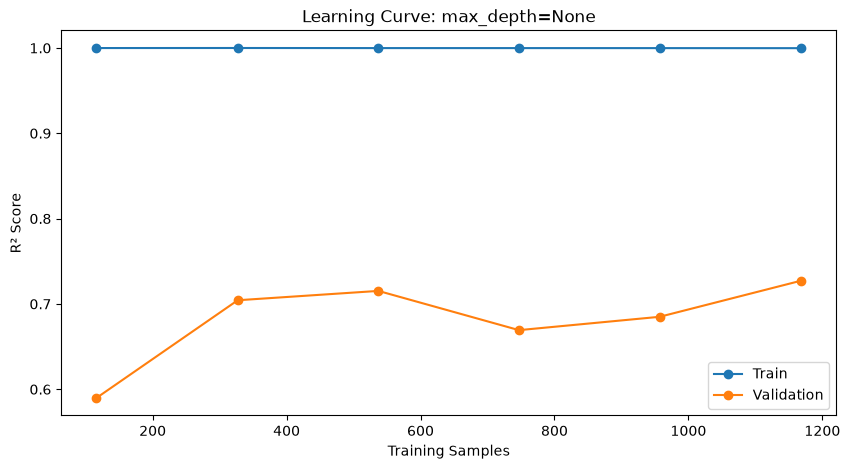

In [6]:
# TODO
# max_depth=None 결정트리의 학습곡선을 그려보세요.

from sklearn.model_selection import validation_curve

# max_depth에 따른 Validation Curve

deep_tree = DecisionTreeRegressor(max_depth = None, random_state = 42)

train_sizes, train_scores, valid_scores = learning_curve(
    deep_tree, X, Y, cv=5,
    train_sizes=np.linspace(0.1, 1.0, 6),
    n_jobs=-1
)

# 학습 점수와 검증 점수의 평균 계산
train_mean_deep = train_scores.mean(axis=1)
valid_mean_deep = valid_scores.mean(axis=1)

plt.figure(figsize=(10, 5))

plt.plot(train_sizes, train_mean_deep, marker="o", label="Train")
plt.plot(train_sizes, valid_mean_deep, marker="o", label="Validation")

# 결과표 생성 (gap = Train - Validation, 두 곡선 사이의 간격)
result_deep = pd.DataFrame({
    "train_size": train_sizes,
    "train_score": train_mean_deep,
    "validation_score": valid_mean_deep,
    "gap": train_mean_deep - valid_mean_deep
})

display(result_deep)

plt.xlabel("Training Samples")
plt.ylabel("R² Score")
plt.title("Learning Curve: max_depth=None")
plt.legend()
plt.show()

*****
학습 샘플 수 116 : Train R²의 평균 0.99 / Validation R² 의 평균 0.59 
-> 판단: 점수차이 0.40

학습 샘플 수 327 : Train R²의 평균 0.99 / validation R²의 평균 0.70
-> 판단: 점수차이 0.29
: 최적의 선택은 둘 다 높거나, 두 점수가 격차가 줄어드는 시점이 가장 좋은 학습 방법, 시간이 될 수 있다.

학습 샘플 수 537 : Train R²의 평균 0.99 / Validation R²의 평균 0.71
-> 판단: 점수차이 0.28

학습 샘플 수 1,168 : Train R²의 평균 0.99 / validation R²의 평균 0.72
-> 판단 점수차이 0.27 
-> 해당 학습 샘플 수를 선택하여 모델링 하는 것이 유리


학습 샘플 수 1,168 : Train R² 의 평균 0.99 / Validation R² 의 평균 0.72 
-> 판단 : 점수차이 0.27 
(해당 학습 샘플 수를 선택하여 모델링 하는 것이 유리)

Train R²의 평균 0.99라는 것의 의미 : 매우 작은 제곱오차로 맞추고 있다. (극소한 차이까지 맞춤)
-> 굉장히 좋은 모델이라면 validation도 0.99로 나왔어야 한다. 그러나 0.27 이라는 차이. 

=> Train R²와 Validation R²의 차이가 0.27이라는 것의 의미:
R²의 차이가 0.27이라고 해서 27%만큼 Validation이 더 틀렸다고 해석하면 안된다.
Train(훈련)의 점수는 0.99점이고 Validation(검증)이 0.27로 차이가 크다는 것은 과적합의 신호

해석: 깊이 제한이 없는 트리 모델의 경우 Train R² 이 거의 1에 가까움. 다만 Validation R²은 0.59~0.72까지 다양함.
학습량 증가에 다른 Validation이 개선의 여지가 보이지만 Train R²과 Validation의 R² 격차를 줄이지 못해
과적합 가능성을 보고 다른 평가지표와 그래프 등을 확인해 보아야 한다.

둘다 높거나, 둘의 격차가 줄어들었을 때, 작을 때 

# Q2. `max_depth=None` 모델에서 데이터를 더 추가하는 것이 도움이 될 가능성이 있는 이유는 무엇인가요?
*답변:*
-> 과적합 상태에서는 모델이 현재 데이터를 지나치게 학습을 한 상태로 학습 데이터가 더 많아지면 현재 학습했던 패턴 외에 패턴들을 학습 할 수가 있기 때문에  Train과 Validation의 격차가 줄어들 수 있다. 
Train이 0.99일 때, ->과적합 판단, 어떻게 해석할 수 있을지 아는 것이 중요. 



---

# 필수 2. 검증곡선과 train-valid gap으로 최적 복잡도 확인

## 배경

검증곡선은 **모델의 하이퍼파라미터를 바꿔가며 Train score와 Validation score의 변화를 확인하는 그래프**입니다.

이번 문제에서는 결정트리의 `max_depth`를 바꾸어 모델 복잡도를 조절합니다.

## 문제 1. `max_depth` 검증곡선을 만드세요.

### 요구사항

1. 다음 `max_depth` 후보를 사용합니다.

```python
param_range = [1, 2, 3, 4, 5, 8, 12, 20, None]
```

2. `validation_curve()`를 사용합니다.
3. `cv=5`를 사용합니다.
4. 각 `max_depth`의 Train score와 Validation score 평균을 계산합니다.
5. `gap = train_mean - valid_mean`을 계산합니다.
6. `max_depth`, `train`, `validation`, `gap`을 DataFrame으로 만듭니다.
7. Train / Validation score를 하나의 그래프에 표시합니다.

### 확인 포인트

- 복잡도가 증가할수록 Train score가 어떻게 변하는가?
- Validation score는 어느 지점까지 좋아지고 이후 어떻게 변하는가?
- train-valid gap은 깊이가 커질수록 어떻게 변하는가?

,max_depth,train,validation,gap
0,1,0.454464,0.429791,0.024674
1,2,0.634121,0.602378,0.031743
2,3,0.733594,0.679087,0.054507
3,4,0.811466,0.733510,0.077956
4,5,0.862431,0.755587,0.106844
5,8,0.948189,0.770884,0.177305
6,12,0.989787,0.746059,0.243728
7,20,0.999686,0.735295,0.264391
8,None,0.999768,0.727192,0.272575


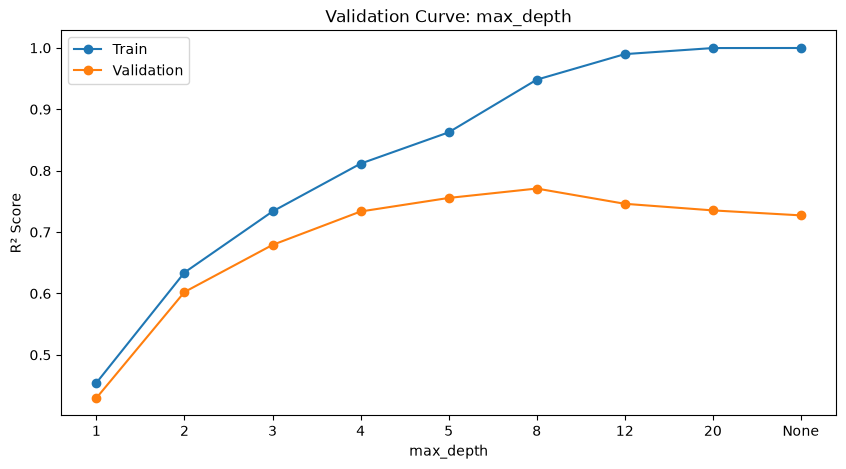

In [7]:
# TODO
# validation_curve()를 이용해 max_depth별 Train / Validation score와 gap을 확인하세요.

from sklearn.model_selection import validation_curve

param_range = [1, 2, 3, 4, 5, 8, 12, 20, None]

tree_model = DecisionTreeRegressor(random_state=42)

train_scores, valid_scores = validation_curve(
    tree_model, X, Y,
    param_name="max_depth",
    param_range=param_range,
    cv=5,
    n_jobs=-1
)

# 학습 점수와 검증 점수의 평균 계산
train_mean = train_scores.mean(axis=1)
valid_mean = valid_scores.mean(axis=1)

# train-valid gap 계산
gap = train_mean - valid_mean

# None은 숫자 축에 놓을 수 없어서 문자열 라벨로 바꿔 사용
param_labels = [str(d) for d in param_range]

plt.figure(figsize=(10, 5))

plt.plot(param_labels, train_mean, marker="o", label="Train")
plt.plot(param_labels, valid_mean, marker="o", label="Validation")

# 결과표 생성
result_vc = pd.DataFrame({
    "max_depth": param_labels,
    "train": train_mean,
    "validation": valid_mean,
    "gap": gap
})

display(result_vc)

plt.xlabel("max_depth")
plt.ylabel("R² Score")
plt.title("Validation Curve: max_depth")
plt.legend()
plt.show()

두 곡선의 목적을 구분
학습곡선과 검증 곡선
학습곡선은 학습자료의 수를 바꾸고 검증곡선 max_depth를 바꾼다.
모델결과를 유지하려는 핵심 조건은 학습 곡선은 트리 깊이 설정, 검증곡선은 데이터와 교차검증 분할
학습곡선의 메인 질문: 데이터가 늘어나면 늘어날수록 성능이 어떻게 달라지는가?
검증곡선의 메인 질문: 오차나 변동이 큰 경우 성능이 어떻게 달라지는가?

|max_depth|Train R²의 평균|Validation R²의 평균|Gap|진단 근거|
|----|----|----|-----|-----|
|1|0.454464	|0.429791|0.024674|두 점수 모두 상대적으로 낮음|  --> gap차이가 가장 낮음. 
|2|0.634121|0.602378|0.031743|깊이 1보다 개선되었지만 표현력 제한|
|3|0.733594|0.679087|0.054507|학습.검증이 함께 상승|
|4|0.811466|0.733510|0.077956|검증 점수가 더 높아짐|
|5|0.862431|0.755587|0.106844|성능과 복잡도 균형을 검토할 수 있는 후보|
|8|**0.948189**|**0.770884** |**0.177305**|현재 9개 후보 중 검증 평균 최고| 
|12|0.989787|0.746059|0.243728|학습은 개선되었으나 검증은 하락|
|20|0.999686|0.735295|0.264391|큰 일반화 차이가 남음|
|None|0.999768|0.727192|0.272575|거의 완벽한 학습 점수와 검증 점수 사이의 큰 gap|

직관적으로 볼 수 있어야 한다. 

*볼드* 처리 : 가장 그나마 후보에 쓸 수 있는 값, 1-20까지 중에, 과적합이 아닌 것은 아님. 쓸만한 깊이.

왜 max depth 8을 선택할 수 있나요?
: Train R²과 Validation R² 이 비교적 격차가 작으며 Validation R² 가 가장 높은 후보를 선택. 

해석 : 복잡도를 높이면 Train R²는 계속 상승하지만, Validation R²는 깊이 8에서 0.77로 가장 높고 그 이후에 감소, 
깊이 1같은 경우 R²값이 Train 과 Test에서 모두 낮아 과소적합을 의심해볼 수 있으며
매우 깊은 deoth에서는 Train R2만 좋아져 과적합의 신호를 포착할 수 있다.
우선 가장 효과가 좋았던 depth 8을 검토해볼 수 있다.  -->gap차이가 높기는 하지만 훈련, 검증 데이터 모두 성능이 좋음, 단순히 검증 데이터에서 더 성능이 좋아요 -> 선택, 근거는 분명하지만, 테스트, 검증 데이터 모두에서 점수가 높고, 비교적 gap도 다른 것에 비해 적었기 떄문에 (선택의 근거, 구체적으로) 
ㅡ> 복잡도를 높인다.== 깊이를 더 깊게 하겠다. 
과적합은 결과만 보고 잘 나왔다고 착각하는 경우가 많아 과적합을 좀 더 경계한다. 

**답변:**  
Q3. Validation score가 가장 높은 `max_depth`는 무엇인가요?
: max_depth 8이 가장 높았다. 
Q4. `max_depth`가 매우 커질수록 train-valid gap이 커지는 이유는 무엇인가요? (모델의 복잡도를 높이면 gap차이가 커지는 이유)
: 결정트리가 깊어질수록 학습 데이터의 세부적인 패턴과 노이즈까지 학습하려고 하기 때문에 
: Train은 지속적으로 높아지지만 새로운 Validate는 충분히 적응하지 못하기 때문에 유지되거나 낮아질 수 있다. 

*복잡도는 모델의 성질이고, 분산은 복잡도를 높인 결과로 커지는 것*
분산은 학습 데이터가 조금만 바뀌어도 모델이 크게 달라지는 정도. 깊은 트리는 주어진 학습 데이터에 딱 맞게 외워 버리기 때문에 이 민감도가 크다. 그 결과가 Train과 Validation의 점수 차이로 드러남.

---

# 과제 1. 모델 상태를 진단하고 대응 전략 선택하기

## 배경

필수 실습에서는 학습곡선과 검증곡선을 이용해 모델의 상태를 확인했습니다.

이번 과제에서는 검증곡선 결과를 이용하여 세 가지 복잡도의 모델 상태를 직접 판단합니다.

> 과제는 필수 실습에서 확인한 결과를 해석하는 수준입니다.

## 문제

다음 세 모델을 확인하세요.

- `max_depth=1`
- `max_depth=8`
- `max_depth=None`

### 요구사항

1. 필수 2에서 만든 `gap_df`에서 세 모델의 Train score, Validation score, gap을 확인합니다.
2. 각 모델을 다음 중 하나로 진단합니다.
   - 과소적합
   - 비교적 적절한 복잡도
   - 과적합
3. 각 모델의 진단 근거를 Train score, Validation score, gap을 이용해 설명합니다.
4. 과소적합 또는 과적합 모델에 대해 교안에서 배운 대응 전략 중 적절한 방향을 하나 이상 작성합니다.

### 확인 포인트

- 점수가 낮고 gap이 작은 경우를 과소적합으로 해석할 수 있는가?
- Train score만 매우 높고 gap이 큰 경우를 과적합으로 해석할 수 있는가?
- Validation score가 높고 gap이 지나치게 크지 않은 지점을 적절한 후보로 볼 수 있는가?
- 진단 후에 대응 전략을 선택했는가?

In [8]:
# TODO
# gap_df에서 max_depth=1, 8, None에 해당하는 결과를 확인하세요.

# 1. 세 모델의 Train, Validation, gap 확인
# 필수 2에서 만든 result_vc 사용

gap_df = result_vc.copy()

selected_depths = ["1", "8", "None"]

selected_models = gap_df[
    gap_df["max_depth"].isin(selected_depths)
]

display(selected_models)


# TODO 2. 각 모델의 상태 진단
# TODO 3. Train, Validation, gap을 근거로 설명
# TODO 4. 대응 전략 작성

diagnosis_df = selected_models.copy()

diagnosis_df["diagnosis"] = [
    "과소적합",
    "비교적 적절한 복잡도",
    "과적합"
]

diagnosis_df["strategy"] = [
    "max_depth를 증가시켜 모델 복잡도를 높인다.",
    "현재 복잡도를 후보로 유지한다.",
    "max_depth를 줄여 모델 복잡도를 낮춘다."
]

display(diagnosis_df)

,max_depth,train,validation,gap
0,1,0.454464,0.429791,0.024674
5,8,0.948189,0.770884,0.177305
8,None,0.999768,0.727192,0.272575


,max_depth,train,validation,gap,diagnosis,strategy
0,1,0.454464,0.429791,0.024674,과소적합,max_depth를 증가시켜 모델 복잡도를 높인다.
5,8,0.948189,0.770884,0.177305,비교적 적절한 복잡도,현재 복잡도를 후보로 유지한다.
8,None,0.999768,0.727192,0.272575,과적합,max_depth를 줄여 모델 복잡도를 낮춘다.


### Q5. 세 모델의 상태를 각각 진단하세요.

| max_depth | 진단 | 근거 |
|---|---|---|
| 1 | 과소적합 | 학습, 검증 데이터 둘 다 결과가 낮게 나왔기 때문이다. |
| 8 |  |  |
| None | 과적합 | 학습 데이터가 시험 데이터보다 결과가 높게 나왔기 때문이다. |

### Q6. 과소적합 모델과 과적합 모델에 각각 어떤 대응 전략을 사용할 수 있나요?

**답변:**  
과소적합은 max_depth를 증가시켜 모델 복잡도를 높이다. 
과적합은 max_depth를 줄여 모델 복잡도를 낮춘다. 

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 편향이 높은 모델은 일반적으로 과소적합과 과적합 중 어느 상태와 관련이 있나요?
: 편향이 높다라는 것은 한쪽으로 치우친 것, 한쪽으로만 많은 지식, 다른 분야는 잘 모름, 한쪽으로 편향이 높다는 것은 
: 일반적으로 과소적합일 가능성이 높다.
-> 편향이 높은 모델은 일반적으로 과소적합과 관련이 있다. 

2. 분산이 높은 모델은 일반적으로 어느 상태와 관련이 있나요?
: 분산이 높은 모델은 일반적으로 과적합과 관련이 있다.

3. 학습곡선에서 Train과 Validation이 낮은 값에서 함께 수렴하면 어떤 상태인가요?
: 과소적합의 신호

4. Train score는 매우 높지만 Validation score가 낮고 gap이 크다면 어떤 상태인가요?
: 과적합의 신호

5. 검증곡선에서 Validation score가 가장 높은 지점은 어떤 의미를 가지나요?
: 현재 후보 중에서 새로운 데이터에 대한 성능이 가장 좋은, 적절한 모델 후보로 선택할 수 있다. 

6. 과적합과 과소적합을 진단하지 않고 바로 처방하면 안 되는 이유는 무엇인가요?
: 과소적합과 과적합은 서로 반대되는 개념
: 과소적합 모델은 더 단순하게 설계하거나, 과적합 모델은 더 복잡하게 만들면 문제가 커질 수 있다. 
: 따라서 어떤 문제를 해결해야하는 지 명확하게 알고 대응해야 한다. 

